In [85]:
!python --version
!echo "code by: Tanvir Anjom Siddique, Lecturer, Dept. of CSE, BAUET"

Python 3.13.5
"code by: Tanvir Anjom Siddique, Lecturer, Dept. of CSE, BAUET"


# Jupyter Notebook: K-Means Clustering Lab


## What is K-Means?

K-Means is an unsupervised machine learning algorithm used to group similar data points into clusters.

- "K" means the number of clusters
- "Means" refers to the average (centroid) of each cluster

It does not require labeled data. Instead, it finds patterns based on similarity.


## What K-Means Does

K-Means tries to:

1. Divide data into K groups
2. Each group has a center (called centroid)
3. Assign each data point to the nearest centroid
4. Update centroid based on assigned points

Goal: Minimize distance between points and their centroid


## How K-Means Works (Concept)

Steps:

1. Choose K (number of clusters)
2. Initialize K centroids randomly
3. Assign each point to nearest centroid
4. Compute new centroids (mean of assigned points)
5. Repeat until centroids do not change


## Example Data

Consider 6 points:

A(1,1), B(2,1), C(4,3), D(5,4), E(3,2), F(8,7)

Let K = 2

Initial centroids:
C1 = (1,1), C2 = (5,4)


## Iteration 1 (Distance Table)

| Point  | Dist to C1 | Dist to C2 | Assigned Cluster     |
| ------ | ---------- | ---------- | -------------------- |
| A(1,1) | 0          | √25 = 5    | C1                   |
| B(2,1) | 1          | √20 ≈ 4.47 | C1                   |
| C(4,3) | √13 ≈ 3.6  | √2 ≈ 1.41  | C2                   |
| D(5,4) | √25 = 5    | 0          | C2                   |
| E(3,2) | √5 ≈ 2.23  | √5 ≈ 2.23  | C1 (tie → choose C1) |
| F(8,7) | √85 ≈ 9.2  | √18 ≈ 4.24 | C2                   |


## New Centroids

Cluster C1: A, B, E
New C1 = ((1+2+3)/3 , (1+1+2)/3) = (2, 1.33)

Cluster C2: C, D, F
New C2 = ((4+5+8)/3 , (3+4+7)/3) = (5.67, 4.67)


## Iteration 2

Repeat distance calculation using new centroids.

Continue until no change in assignments.


## Where K-Means is Used

- Customer segmentation
- Image compression
- Document clustering
- Anomaly detection
- Market analysis


## Where K-Means Cannot Be Used

- Non-spherical clusters
- Different cluster sizes
- Presence of noise/outliers
- Categorical data (without preprocessing)

> Non-spherical clusters:<br>

K-Means assumes that clusters are roughly circular (or spherical in higher dimensions) and evenly distributed around a central point (centroid). It uses distance (usually Euclidean) to assign points to the nearest centroid. If the actual data forms irregular shapes such as elongated, crescent, or spiral clusters, K-Means fails to capture the true structure. It will incorrectly divide such clusters into multiple parts or merge different ones.

> Different cluster sizes:<br>

K-Means works best when all clusters have similar sizes and densities. When clusters vary significantly in size, the algorithm tends to assign more points to larger clusters and may split them incorrectly. Smaller clusters may be ignored or merged into larger ones because centroids are influenced by the number of data points.

> Presence of noise or outliers:<br>

K-Means is highly sensitive to outliers because it uses the mean (centroid) as the representative of a cluster. Even a few extreme values can shift the centroid away from the true center, leading to incorrect cluster assignments. As a result, clusters become distorted and less meaningful.

> Categorical data (without preprocessing)<br>

K-Means relies on numerical distance calculations, such as Euclidean distance. Categorical data (e.g., color, type, label) does not have a natural notion of distance in this sense. Without proper preprocessing techniques like encoding (e.g., one-hot encoding), K-Means cannot be directly applied. Even after encoding, the distance interpretation may still not be meaningful.


# Evaluation of K-Means Clustering

## Using WCSS and Silhouette Score

K-Means clustering needs a proper value of **K (number of clusters)**.  
Two common methods to evaluate clustering quality are:

- WCSS (Within-Cluster Sum of Squares)
- Silhouette Score

## 1. WCSS (Within-Cluster Sum of Squares)

### What is WCSS?

WCSS measures how close the data points are to their cluster center.  
It calculates the total squared distance between each point and its cluster centroid.

### Formula

$$
WCSS = \sum_{k=1}^{K} \sum_{x_i \in C_k} \|x_i - \mu_k\|^2
$$

### Simple Idea

- Smaller WCSS → points are closer → clusters are compact
- Larger WCSS → points are spread out → clusters are weak

### How it is Used

1. Run K-Means for different values of K (e.g., 1 to 10)
2. Calculate WCSS for each K
3. Plot a graph of:
   - X-axis → K
   - Y-axis → WCSS

4. Look for the **"elbow point"**
   - At first, WCSS decreases quickly
   - Then it slows down
   - The bend (elbow) is the best K

### Limitation

- WCSS always decreases when K increases
- So, it cannot alone decide the best K

## 2. Silhouette Score

### What is Silhouette Score?

It measures how well a point fits in its cluster compared to other clusters.

### Formula

$$
s(i) = \frac{b(i) - a(i)}{\max(a(i), b(i))}
$$

### Meaning of Terms

- \( a(i) \): average distance to points in the same cluster
- \( b(i) \): average distance to points in the nearest other cluster

### Score Range

- **+1** → very good clustering
- **0** → point is between clusters
- **-1** → wrong cluster assignment

### How it is Used

1. Run K-Means for different values of K
2. Compute average silhouette score for each K
3. Choose the K with the **highest score**

## 3. Key Difference

| Aspect           | WCSS                     | Silhouette Score         |
| ---------------- | ------------------------ | ------------------------ |
| Measures         | Compactness              | Compactness + Separation |
| Output           | Value (decreases with K) | Value between -1 and 1   |
| Selection Method | Elbow method             | Maximum score            |

## 4. Final Understanding

- WCSS helps find a **range of good K values**
- Silhouette Score helps choose the **best K**

### Simple Workflow

1. Use WCSS → find elbow point
2. Use Silhouette Score → confirm best K

## Summary

- WCSS checks how tight the clusters are
- Silhouette Score checks how correct the clustering is
- Using both together gives better results


## Selecting Optimal K

### Elbow Method

1. Run K-Means for different K values
2. Plot K vs WCSS
3. Find elbow point

### Silhouette Method

Choose K with highest silhouette score


In [86]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)
data = np.random.rand(100, 2) * 10

print(data[:5])

[[3.74540119 9.50714306]
 [7.31993942 5.98658484]
 [1.5601864  1.5599452 ]
 [0.58083612 8.66176146]
 [6.01115012 7.08072578]]


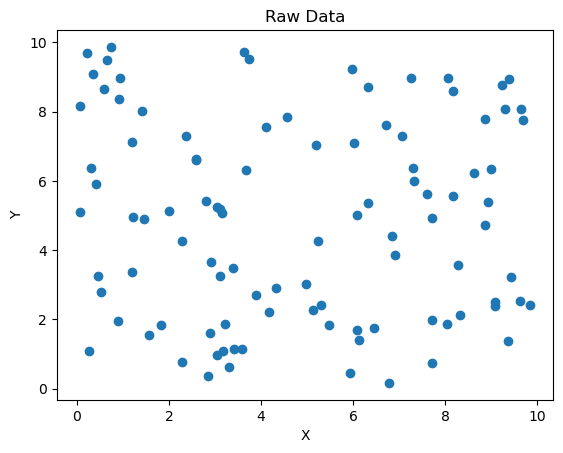

In [87]:
plt.scatter(data[:,0], data[:,1])
plt.title("Raw Data")
plt.xlabel("X")
plt.ylabel("Y")
plt.show()

In [ ]:
def kmeans(X, k, max_iters=100):
    centroids = X[np.random.choice(len(X), k, replace=False)]

    for _ in range(max_iters):
        distances = np.linalg.norm(X[:, None] - centroids, axis=2)
        labels = np.argmin(distances, axis=1)

        new_centroids = np.array([X[labels == i].mean(axis=0) for i in range(k)])

        if np.all(centroids == new_centroids):
            break

        centroids = new_centroids

    return labels, centroids


In [ ]:
k, replace=False)]

    for _ in range(max_iters):
        distances = np.linalg.norm(X[:, None] - centroids, axis=2)
        labels = np.argmin(distances, axis=1)

        new_centroids = np.array([X[labels == i].mean(axis=0) for i in range(k)])

        if np.all(centroids == new_centroids):
            break

        centroids = new_centroids

    return labels, centroids


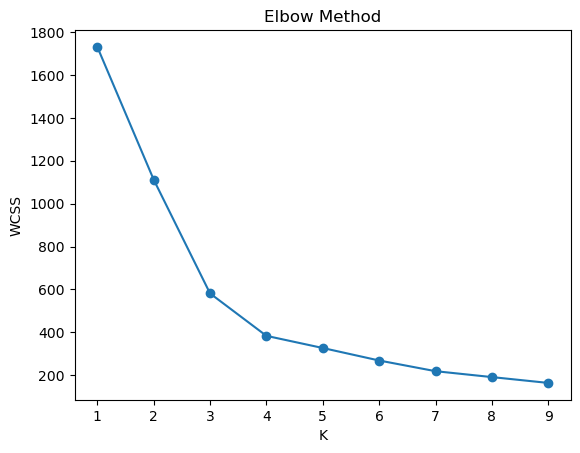

In [89]:
def compute_wcss(X, k):
    labels, centroids = kmeans(X, k)
    wcss = 0

    for i in range(k):
        cluster_points = X[labels == i]
        wcss += np.sum((cluster_points - centroids[i])**2)

    return wcss

wcss_values = []
k_range = range(1, 10)

for k in k_range:
    wcss_values.append(compute_wcss(data, k))

plt.plot(k_range, wcss_values, marker='o')
plt.title("Elbow Method")
plt.xlabel("K")
plt.ylabel("WCSS")
plt.show()

In [ ]:
from sklearn.metrics import silhouette_score

# already computed
k = 4
labels, centroids = kmeans(data, k)

print("Centroids:\n", centroids)
print("Labels:\n", labels)

# WCSS Calculation
wcss = 0
for i in range(k):
    cluster_points = data[labels == i]
    wcss += np.sum((cluster_points - centroids[i])**2)

print("WCSS:", wcss)

# Silhouette Score
sil_score = silhouette_score(data, labels)
print("Silhouette Score:", sil_score)

Centroids:
 [[1.85209431 7.22280654]
 [7.8378364  7.3812559 ]
 [7.51187305 2.57045258]
 [2.74520439 2.1308078 ]]
Labels:
 [0 1 3 0 1 0 2 3 0 3 2 3 0 0 2 2 0 1 3 2 0 0 0 0 2 1 1 1 3 3 3 2 0 0 0 2 0
 1 2 3 1 3 3 1 2 0 1 2 2 3 0 0 2 0 3 3 1 1 2 1 1 3 3 1 0 3 3 2 1 0 2 3 3 2
 3 2 0 2 1 0 0 1 0 3 0 2 3 2 2 2 3 1 0 1 2 0 1 3 1 1]
WCSS: 378.18689301285934
Silhouette Score: 0.42430208228214


Explanation (for students)

- WCSS measures how close points are to their centroid
- Lower value means better clustering
- Silhouette Score measures how well-separated clusters are
- Value close to 1 means good clustering


In [91]:
# Classifying a New Unknown Point
# new unseen data point
new_point = np.array([6, 5])

# compute distance from each centroid
distances = np.linalg.norm(centroids - new_point, axis=1)

# find nearest centroid
assigned_cluster = np.argmin(distances)

print("New Point:", new_point)
print("Distances from centroids:", distances)
print("Assigned Cluster:", assigned_cluster)

New Point: [6 5]
Distances from centroids: [4.70595267 3.00799307 2.86154867 4.33888907]
Assigned Cluster: 2


Explanation:

- The new point is compared with all centroids
- Distance is calculated
- The nearest centroid determines its cluster


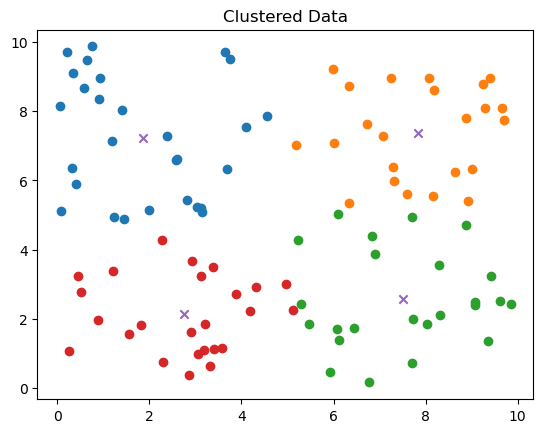

In [92]:
for i in range(k):
    plt.scatter(data[labels == i][:,0], data[labels == i][:,1])

plt.scatter(centroids[:,0], centroids[:,1], marker='x')
plt.title("Clustered Data")
plt.show()

## Plot existing and new points


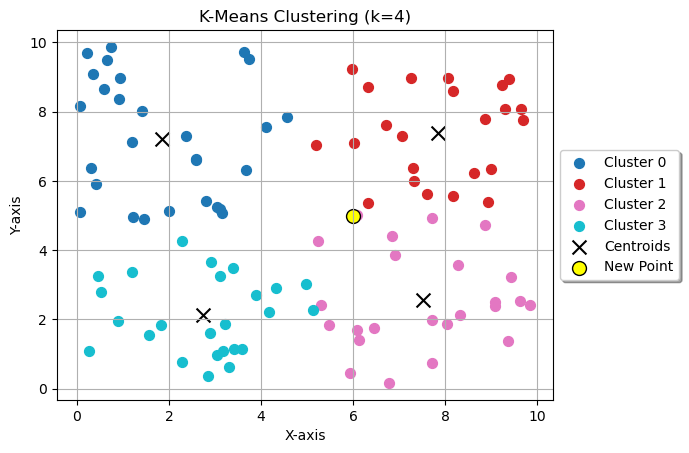

In [93]:
# ensure inline plotting in Jupyter
# makes your graphs appear directly inside the notebook cell, instead of opening in a separate window
%matplotlib inline
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import numpy as np

# Example: k, labels, centroids, new_point already computed
# k = 4
# labels, centroids = kmeans(data, k)
# new_point = np.array([6, 5])

# choose colormap for k clusters
cmap = cm.get_cmap('tab10', k)

# plot each cluster dynamically
for i in range(k):
    plt.scatter(
        data[labels == i][:, 0],
        data[labels == i][:, 1],
        color=cmap(i),
        label=f'Cluster {i}',
        s=50
    )

# plot centroids
plt.scatter(
    centroids[:, 0],
    centroids[:, 1],
    marker='x',
    s=100,
    color='black',
    label='Centroids'
)

# plot new unseen point
plt.scatter(
    new_point[0],
    new_point[1],
    marker='o',
    s=100,
    color='yellow',
    edgecolor='black',
    label='New Point'
)

# labels, title, legend
plt.xlabel("X-axis")
plt.ylabel("Y-axis")
plt.title(f"K-Means Clustering (k={k})")
# plt.legend()
# Legend on the right, outside the plot
plt.legend(
    loc='center left',          # anchor point on plot's left center
    bbox_to_anchor=(1, 0.5),    # move legend outside to right
    ncol=1,                     # 1 column
    fancybox=True,              # rounded legend box
    shadow=True
)
plt.grid(True)

# show the plot
plt.show()

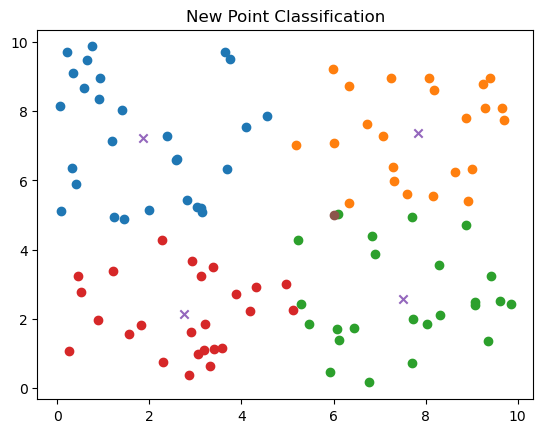

In [94]:
# plot existing clusters
for i in range(k):
    plt.scatter(data[labels == i][:,0], data[labels == i][:,1])

# plot centroids
plt.scatter(centroids[:,0], centroids[:,1], marker='x')

# plot new point
plt.scatter(new_point[0], new_point[1], marker='o')

plt.title("New Point Classification")
plt.show()

In [95]:
import warnings
warnings.filterwarnings("ignore")

In [96]:
import os
os.environ["OMP_NUM_THREADS"] = "1"
# UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. 
# You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
from sklearn.cluster import KMeans

kmeans_model = KMeans(n_clusters=4, random_state=42)
kmeans_model.fit(data)

labels = kmeans_model.labels_
centroids = kmeans_model.cluster_centers_

print("Centroids:\n", centroids)

Centroids:
 [[7.76302209 7.18934527]
 [3.02218023 2.20759545]
 [1.85209431 7.22280654]
 [7.92045796 2.27282306]]


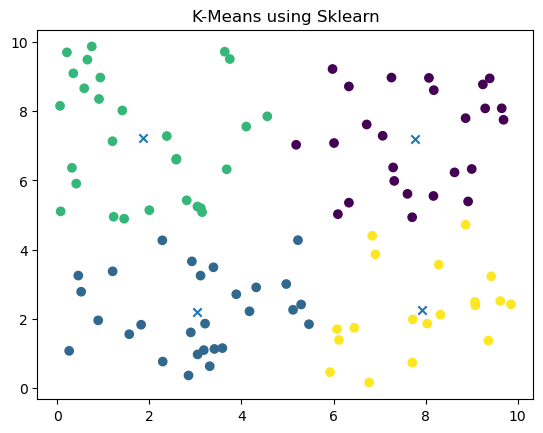

In [97]:
plt.scatter(data[:,0], data[:,1], c=labels)
plt.scatter(centroids[:,0], centroids[:,1], marker='x')
plt.title("K-Means using Sklearn")
plt.show()